In [1]:
import torch 
import sys 
import pandas as pd 
import numpy as np 
import networkx as nx 

print(f'torch=={torch.__version__}') 
print(f'pandas=={pd.__version__}') 
print(f'numpy=={np.__version__}') 
print(f'networkx=={nx.__version__}') 

import tqdm 
import matplotlib.pyplot as plt 
from itertools import chain 

sys.path.append('.') 
from agfn.gflownet import GFlowNet 
from agfn.gym import MAG, LogReward 
from agfn.models import ForwardPolicy, BackwardPolicy  

torch==2.3.0+cu121
pandas==1.5.3
numpy==1.23.5
networkx==3.1


/home/alunos/.pyenv/versions/3.10.12/envs/torch/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') 
print(f'Device: {device}') 

Device: cuda


This tutorial shows how to train an AGFN using a custom dataset. In the near future, it will be expanded and improved. 

## Load the data

In [3]:
torch.set_default_dtype(torch.float64) 

In [4]:
data = pd.read_csv('data/chain4_dat01.csv') 
node_labels = data.columns.tolist() 
data = torch.tensor(data.values, device=device, dtype=torch.get_default_dtype()) 
num_nodes = data.shape[1] 
print(f'Number of variables: {num_nodes}') 

Number of variables: 4


## Instantiate the model 

In [5]:
pf = ForwardPolicy(num_nodes, num_layers=2, hidden_dim=256, device=device) 
pb = BackwardPolicy(device) 
gflownet = GFlowNet(pf, pb, criterion='tb', device=device) 

In [6]:
create_env = lambda batch_size=64: MAG(num_nodes, batch_size, log_reward, device=device) 

In [7]:
log_reward = LogReward(dataset=data, device=device) 
log_reward.warmup(gflownet, create_env, 32)

## Train the model 

In [8]:
def train(gflownet, create_env, epochs, lr=1e-3, lr_logz=1e-1, use_scheduler=False):
    optimizer = torch.optim.Adam([
        {'params': chain(gflownet.pf.parameters(), gflownet.pb.parameters()), 'lr': lr}, 
        {'params': gflownet.log_z, 'lr': lr_logz}]) 
    scheduler = torch.optim.lr_scheduler.PolynomialLR(optimizer, total_iters=epochs) 

    losses = list() 
    pbar = tqdm.tqdm(range(epochs), disable=False) 
    for epoch in pbar: 
        optimizer.zero_grad() 
        env = create_env() 
        loss = gflownet(env) 
        loss.backward()     
        optimizer.step() 
        pbar.set_postfix(loss=loss.item()) 
        # Update the exploration rate 
        losses.append(loss.item()) 
        if use_scheduler: 
            scheduler.step() 
    return losses  

In [9]:
losses = train(gflownet, create_env, epochs=int(1e3)) 

100%|██████████| 1000/1000 [00:33<00:00, 30.30it/s, loss=0.0165]


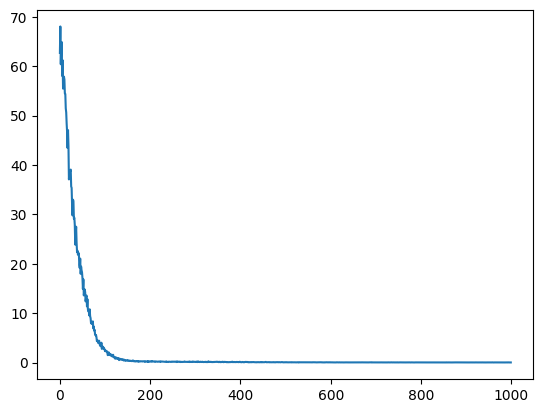

In [10]:
plt.plot(losses) 

## Sample from target 

In [11]:
env = create_env() 
env = gflownet.sample(env) 

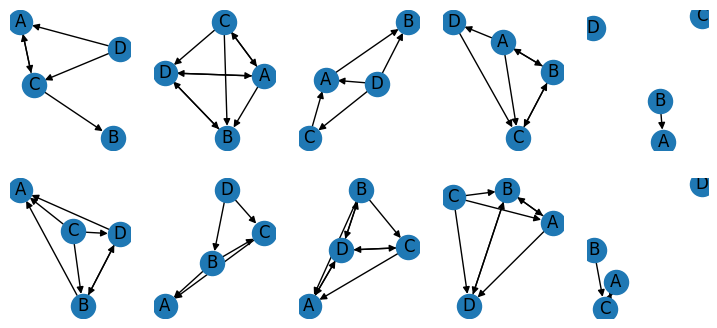

In [12]:
plt.figure(figsize=(9, 4)) 
indices = np.random.permutation(env.batch_size)[:10] 
for e, i in enumerate(indices): 
    plt.subplot(2, 5, e + 1)  
    env.draw(i, labels=node_labels) 